# Random Signals and LTI-Systems

*This jupyter notebook is part of a [collection of notebooks](../index.ipynb) on various topics of Digital Signal Processing. Please direct questions and suggestions to [Sascha.Spors@uni-rostock.de](mailto:Sascha.Spors@uni-rostock.de).*

## Noise Reduction of Speech Signals with the Wiener Filter

The [Wiener filter](wiener_filter.ipynb) has been derived under the assumption that all signals involved are wide-sense stationary (WSS). Many signals of practical interest do not fulfill this assumption. A prominent example are speech signals. Their statistical properties, e.g. their PSD, change permanently due to the sequence of vowels, consonants and pauses. However, speech can be regarded as approximately stationary within short time intervals of about 20 to 40 ms. This property is known as *short-time stationarity*. A common approach to apply techniques derived for WSS signals to non-stationary signals is *block-based processing*. The signal is split into short overlapping segments (blocks), each block is processed individually under the assumption that the signal is stationary within the block, and the processed blocks are finally recombined into a continuous output signal. This notebook illustrates block-based processing by the example of reducing additive background noise in a speech signal by a Wiener filter that is designed in the frequency domain.

### Signal Model

The observed signal $x[k]$ is given as superposition of the speech signal $s[k]$ and additive noise $n[k]$

\begin{equation}
x[k] = s[k] + n[k]
\end{equation}

This is the special case $G(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = 1$ of the signal model of the [Wiener filter](wiener_filter.ipynb#Signal-Model). The following assumptions are made:

* the noise $n[k]$ is WSS, hence its PSD $\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ does not change over time,
* the noise $n[k]$ is uncorrelated from the speech signal $s[k]$,
* the recording starts with a section which contains only noise, the speech signal starts after $T_0 = 5$ seconds.

For a pass-through $G(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = 1$ the transfer function of the Wiener filter [has been derived as](wiener_filter.ipynb#Interpretation)

\begin{equation}
H(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = \frac{\Phi_{ss}(\mathrm{e}^{\,\mathrm{j}\,\Omega})}{\Phi_{ss}(\mathrm{e}^{\,\mathrm{j}\,\Omega}) + \Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})}
\end{equation}

Since $s[k]$ and $n[k]$ are uncorrelated, the PSD of the observed signal is given as $\Phi_{xx}(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = \Phi_{ss}(\mathrm{e}^{\,\mathrm{j}\,\Omega}) + \Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$. Introducing this into above equation yields an alternative formulation of the Wiener filter

\begin{equation}
H(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = 1 - \frac{\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})}{\Phi_{xx}(\mathrm{e}^{\,\mathrm{j}\,\Omega})}
\end{equation}

which is very convenient for the problem at hand: The PSD $\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ of the noise can be estimated from the noise-only segment at the beginning of the recording, the PSD $\Phi_{xx}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ of the observed signal is directly accessible. The PSD $\Phi_{ss}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ of the speech signal, which is not known, is not required. Since the speech signal is non-stationary, $\Phi_{ss}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ and consequently $\Phi_{xx}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ change over time. The Wiener filter has therefore to be computed individually for each block. In contrast, the noise PSD must be estimated only once.

### Block-Based Processing

The block-based processing is performed in the frequency domain by the [short-time Fourier transform](../spectral_analysis_deterministic_signals/stft.ipynb) (STFT). The overall procedure consists of the following steps:

1. **Analysis:** The observed signal $x[k]$ is split into overlapping blocks of length $L$ which are shifted by the hop size $R$. Each block is weighted by the analysis window $w[k]$ and transformed by the discrete Fourier transform (DFT). This yields the STFT
\begin{equation}
X[\mu, n] = \sum_{k=0}^{L-1} x[k + n R] \, w[k] \, \mathrm{e}^{-\mathrm{j} \frac{2 \pi}{L} \mu k}
\end{equation}
where $\mu$ denotes the frequency index and $n$ the block index.
2. **Processing:** The spectrum of each block is weighted by the transfer function of the Wiener filter for this block $Y[\mu, n] = H[\mu, n] \cdot X[\mu, n]$.
3. **Synthesis:** Each block is transformed back into the time domain by the inverse DFT, weighted by the synthesis window $w[k]$ and added at its original position to the output signal $y[k]$. This technique is known as [*weighted overlap-add* (WOLA)](https://ccrma.stanford.edu/~jos/OLA/Weighted_OverLap_Add_WOLA.html).

Without processing $H[\mu, n] = 1$, the output $y[k]$ should be equal to the input $x[k]$. This *perfect reconstruction* property requires that the overlapping products of analysis and synthesis window sum up to a constant
\begin{equation}
\sum_{n=-\infty}^{\infty} w^2[k - n R] = 1
\end{equation}
The square root of the (periodic) [Hann window](../spectral_analysis_deterministic_signals/window_functions.ipynb) with an overlap of 50 %, i.e. $R = L/2$, fulfills this condition. Using the window also for synthesis has the benefit that discontinuities at the block borders, introduced by the processing, are smoothly faded out. The block length $L$ is a compromise. On the one hand, it should be short enough such that the speech signal can be regarded as stationary within a block. On the other hand, it should be long enough to provide a reasonable frequency resolution. Block lengths of 20 to 40 ms are typically used for speech signals.

### Implementation

The following functions implement the STFT and its inverse by WOLA. Within `stft()` the signal is padded by zeros at the beginning and the end such that all samples of $x[k]$ are covered by the same number of overlapping blocks. The function `istft()` computes the output signal by overlap-adding the windowed inverse DFTs of the blocks, and removes the samples resulting from the zero-padding. Since the signals are real-valued, only the DFT coefficients for $0 \leq \mu \leq \lfloor L/2 \rfloor$ are computed by the real-valued FFT `np.fft.rfft()`. The remaining coefficients follow from the symmetry $X[L - \mu, n] = X^*[\mu, n]$. For even $L$, as used in the following, the last coefficient $\mu = L/2$ corresponds to half the sampling frequency.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
import soundfile as sf


L = 256  # block length
R = L // 2  # hop size
T0 = 5  # duration of the noise-only segment in s
SNR = 5  # SNR during speech activity in dB
alpha = 0.8  # smoothing constant for PSD of observed signal
Hmin = 10 ** (-20 / 20)  # spectral floor


def stft(x, w, R):
    # short-time Fourier transform of x with window w and hop size R
    L = len(w)
    xp = np.concatenate((np.zeros(L - R), x, np.zeros(L)))
    N = (len(xp) - L) // R + 1  # number of blocks
    X = np.zeros((L // 2 + 1, N), dtype=complex)
    for n in range(N):
        X[:, n] = np.fft.rfft(w * xp[n * R : n * R + L])
    return X


def istft(X, w, R, length):
    # inverse short-time Fourier transform by weighted overlap-add
    L = len(w)
    N = X.shape[1]
    y = np.zeros((N - 1) * R + L)
    for n in range(N):
        y[n * R : n * R + L] += w * np.fft.irfft(X[:, n], n=L)
    return y[L - R : L - R + length]

In the following, the window $w[k]$ is chosen as the square root of the periodic Hann window of length $L = 256$ with 50 % overlap $R = 128$. For a sampling frequency of $f_\text{s} = 8$ kHz this corresponds to a block length of 32 ms. The plot shows the products $w^2[k - n R]$ of analysis and synthesis window for consecutive blocks $n$ and their sum. Each sample $k$ is covered by two blocks. Except for the beginning and the end, the sum is equal to one, which confirms the perfect reconstruction condition. In `stft()` the signal is padded by $L - R$ zeros at the beginning, such that the first samples of $x[k]$ are also covered by two blocks.

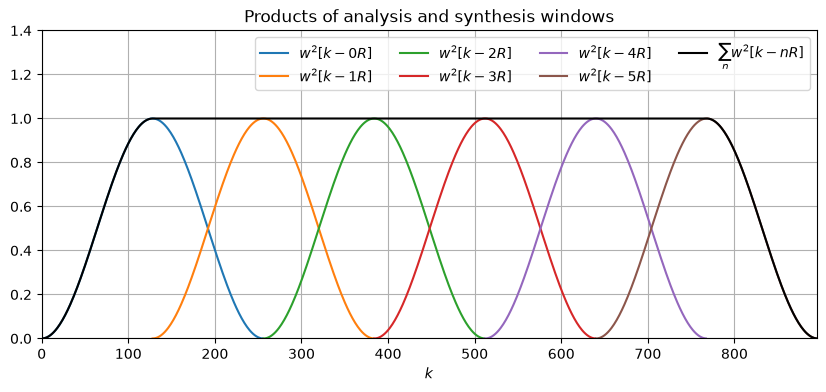

In [2]:
w = np.sqrt(sig.windows.hann(L, sym=False))  # analysis/synthesis window

# plot products of analysis and synthesis windows and their sum
Nb = 6  # number of blocks to plot

k = np.arange((Nb - 1) * R + L)
wsum = np.zeros(len(k))
plt.figure(figsize=(10, 4))
for b in range(Nb):
    plt.plot(b * R + np.arange(L), w**2, label=r"$w^2[k - {} R]$".format(b))
    wsum[b * R : b * R + L] += w**2
plt.plot(k, wsum, "k", label=r"$\sum_n w^2[k - n R]$")
plt.title("Products of analysis and synthesis windows")
plt.xlabel(r"$k$")
plt.xlim([0, k[-1]])
plt.ylim([0, 1.4])
plt.legend(loc="upper right", ncol=4)
plt.grid()

### Observed Signal

The observed signal is constructed from a recorded speech signal $s[k]$ with a sampling frequency of $f_\text{s} = 8$ kHz. It is preceded by a pause of $T_0 = 5$ seconds. As a typical model for acoustic background noise $n[k]$, [pink noise](power_spectral_densities.ipynb#Example---Pink-Noise) is used. It is generated by filtering normally distributed white noise with variance $N_0$ with a recursive filter $H_\text{n}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ which approximates a PSD inversely proportional to the frequency. The PSD of the noise is [given as](power_spectral_densities.ipynb) $\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = N_0 \cdot | H_\text{n}(\mathrm{e}^{\,\mathrm{j}\,\Omega}) |^2$. The noise is scaled such that the signal-to-noise ratio (SNR) during the speech activity is 5 dB. 
The code below constructs the observed signal $x[k]$ and plots its spectrogram $|X[\mu, n]|$ computed by the `stft()` function introduced above. The noise-only segment and the regions of speech activity are clearly visible. The noise power is concentrated at low frequencies, where it masks the speech components.

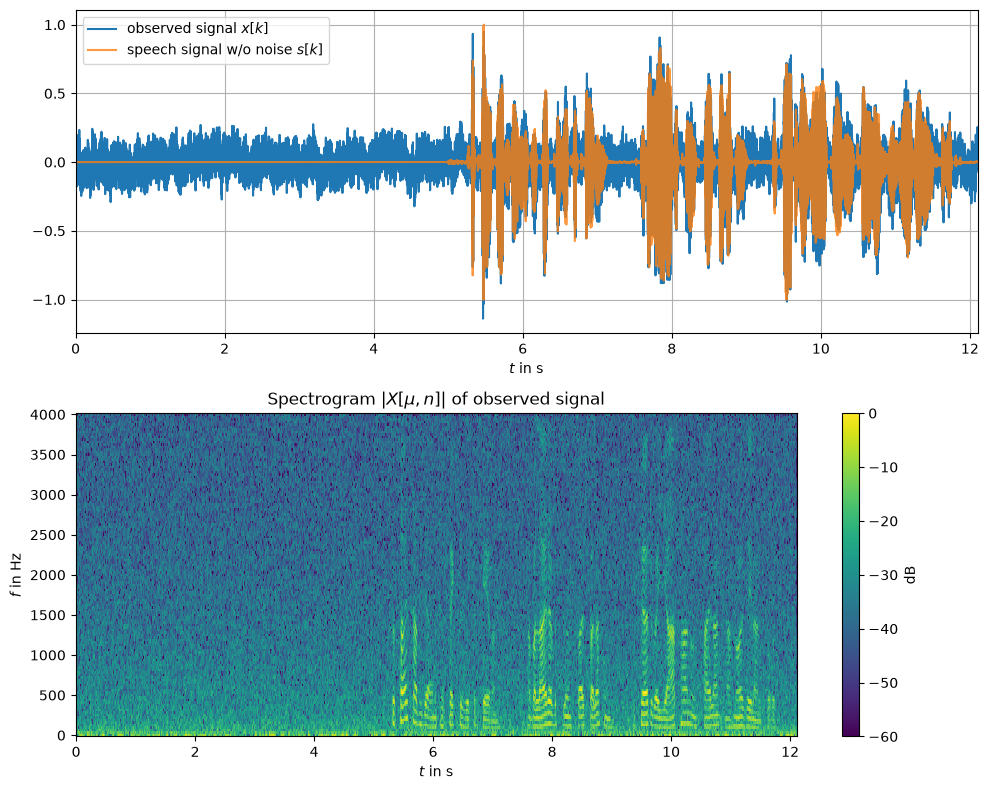

In [3]:
# read speech signal and prepend pause
s, fs = sf.read("../data/speech_8k.wav")
s = s / np.max(np.abs(s))
s = np.concatenate((np.zeros(T0 * fs), s))
# generate pink noise by filtering white noise
# see http://www.firstpr.com.au/dsp/pink-noise/#Filtering
a = np.poly([0.99572754, 0.94790649, 0.53567505])  # denominator coefficients
b = np.poly([0.98443604, 0.83392334, 0.07568359])  # numerator coefficients
np.random.seed(2)
v = np.random.normal(size=len(s))
n = sig.lfilter(b, a, v)
# scale noise to desired SNR
scale = np.sqrt(np.var(s[T0 * fs :]) / np.var(n) * 10 ** (-SNR / 10))
n = scale * n
N0 = scale**2  # variance of the white noise
# observed signal
x = s + n


def plot_spectrogram(X, title, vmin=-60):
    # plot spectrogram |X[mu, n]| in dB normalized to its maximum
    t = np.arange(X.shape[1]) * R / fs
    f = np.fft.rfftfreq(L, 1 / fs)
    XdB = 20 * np.log10(np.abs(X) / np.max(np.abs(X)) + 1e-12)
    plt.pcolormesh(t, f, XdB, vmin=vmin, vmax=0, shading="auto")
    plt.title(title)
    plt.xlabel(r"$t$ in s")
    plt.ylabel(r"$f$ in Hz")
    cb = plt.colorbar()
    cb.set_label("dB")


# compute STFT of observed signal
X = stft(x, w, R)

# plot observed signal and its spectrogram
t = np.arange(len(x)) / fs
plt.figure(figsize=(10, 8))
plt.subplot(211)
plt.plot(t, x, label=r"observed signal $x[k]$")
plt.plot(t, s, label=r"speech signal w/o noise $s[k]$", alpha=0.8)
plt.xlabel(r"$t$ in s")
plt.xlim([0, t[-1]])
plt.legend(loc="upper left")
plt.grid()
plt.subplot(212)
plot_spectrogram(X, r"Spectrogram $|X[\mu, n]|$ of observed signal")
plt.tight_layout()

### Estimation of the Noise PSD

The PSD $\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ of the noise is estimated from the noise-only segment $0 \leq t < T_0$. Within this segment the observed signal is given as $x[k] = n[k]$. The squared magnitudes of the STFT coefficients $|X[\mu, n]|^2$ constitute (modified) [periodograms](../spectral_estimation_random_signals/periodogram.ipynb) of the individual blocks. Averaging them over all blocks of the noise-only segment yields the [Welch estimate](../spectral_estimation_random_signals/welch_method.ipynb) of the PSD

\begin{equation}
\hat{\Phi}_{nn}[\mu] = \frac{1}{|\mathcal{N}_0|} \sum_{n \in \mathcal{N}_0} |X[\mu, n]|^2
\end{equation}

where $\mathcal{N}_0$ denotes the set of block indices within the noise-only segment and $|\mathcal{N}_0|$ their number. Since the estimate is computed with the same window $w[k]$ that is used for processing, $\hat{\Phi}_{nn}[\mu]$ and the per-block quantities $|X[\mu, n]|^2$ used later on share the same scaling. For a comparison with the true PSD $\Phi_{nn}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$, the estimate has to be normalized by the energy $\sum_k w^2[k]$ of the window. The first block is excluded from the average since it contains the zeros padded by `stft()`.

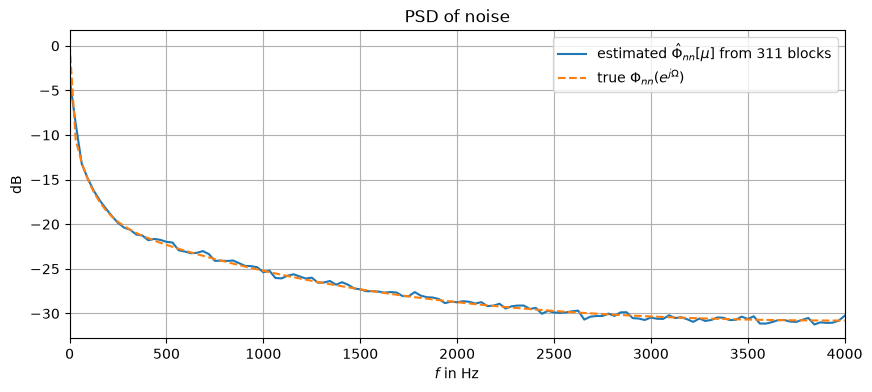

In [4]:
# indices of blocks which lie completely in the noise-only segment
idx_noise = np.arange(1, T0 * fs // R)
# Welch estimate of noise PSD
Pnn = np.mean(np.abs(X[:, idx_noise]) ** 2, axis=1)

# true PSD of noise
Om = np.linspace(0, np.pi, L // 2 + 1)
Om, Hn = sig.freqz(b, a, worN=Om)
Pnn_true = N0 * np.abs(Hn) ** 2

# plot PSDs
f = np.fft.rfftfreq(L, 1 / fs)
plt.figure(figsize=(10, 4))
plt.plot(
    f,
    10 * np.log10(Pnn / np.sum(w**2)),
    label=r"estimated $\hat{\Phi}_{nn}[\mu]$ from " + str(len(idx_noise)) + " blocks",
)
plt.plot(f, 10 * np.log10(Pnn_true), "--", label=r"true $\Phi_{nn}(e^{j \Omega})$")
plt.title("PSD of noise")
plt.xlabel(r"$f$ in Hz")
plt.ylabel("dB")
plt.xlim([0, fs / 2])
plt.legend()
plt.grid()

The estimated PSD agrees well with the true PSD. The remaining fluctuations are due to the finite number of averaged blocks.

### Block-Wise Wiener Filter

The PSD $\Phi_{xx}(\mathrm{e}^{\,\mathrm{j}\,\Omega})$ of the observed signal has to be estimated for each block $n$ individually, since the speech signal is non-stationary. The simplest estimate is the periodogram $|X[\mu, n]|^2$ of the block. However, the periodogram of a single block is known to exhibit a [high variance](../spectral_estimation_random_signals/periodogram.ipynb). Averaging over many blocks, as for the noise, is not possible since the PSD changes over time. A compromise is a *recursive average* over the preceding blocks

\begin{equation}
\hat{\Phi}_{xx}[\mu, n] = \alpha \cdot \hat{\Phi}_{xx}[\mu, n-1] + (1 - \alpha) \cdot |X[\mu, n]|^2
\end{equation}

where the smoothing constant $0 \leq \alpha < 1$ controls the trade-off between variance of the estimate and its ability to follow the changes of the speech signal. For $\alpha = 0$ the periodogram of the current block is used. The transfer function of the Wiener filter for block $n$ is then given as

\begin{equation}
H[\mu, n] = \max \left\{ 1 - \frac{\hat{\Phi}_{nn}[\mu]}{\hat{\Phi}_{xx}[\mu, n]}, H_\text{min} \right\}
\end{equation}

Due to estimation errors, the ratio $\hat{\Phi}_{nn}[\mu] / \hat{\Phi}_{xx}[\mu, n]$ can become larger than one. This would result in a negative transfer function, which has no meaning since $H(\mathrm{e}^{\,\mathrm{j}\,\Omega}) = \Phi_{ss} / (\Phi_{ss} + \Phi_{nn})$ is non-negative by definition. The transfer function is therefore limited from below by the *spectral floor* $H_\text{min} \geq 0$. A floor larger than zero furthermore ensures that a small amount of background noise remains. This sounds more natural than a complete suppression of the noise in speech pauses.

Smoothing and spectral floor are furthermore required to avoid an artifact which is characteristic for this type of noise reduction. Without smoothing $\alpha = 0$, the PSD of the observed signal is estimated by the periodogram $|X[\mu, n]|^2$ of the individual blocks. Due to the high variance of the periodogram, the estimate $|X[\mu, n]|^2$ randomly exceeds the noise PSD $\hat{\Phi}_{nn}[\mu]$ in the noise-only regions. At these time-frequency points the Wiener filter passes the noise, while it suppresses the noise at the neighboring points. The residual noise consists of isolated spectral peaks which randomly appear and vanish from block to block. It has a tonal character and is perceived as very annoying. This effect is known as *musical noise*. The recursive smoothing reduces the variance of $\hat{\Phi}_{xx}[\mu, n]$ and hence the number of random peaks. The spectral floor $H_\text{min} > 0$ limits the contrast between the peaks and the suppressed surrounding. Consequently, the residual noise is spread more uniformly over time and frequency, and its character resembles the original noise. The spectral floor reduces the musical noise at the cost of a lower noise attenuation.

The function `wiener_gain()` computes the transfer functions $H[\mu, n]$ for all blocks. The function `wiener_denoise()` combines all steps: STFT analysis, computation of the Wiener filter, multiplication in the frequency domain and synthesis by the inverse STFT.

In [5]:
def wiener_gain(X, Pnn, alpha, Hmin):
    # block-wise transfer function of Wiener filter
    Pxx = np.zeros(X.shape)
    H = np.zeros(X.shape)
    Pxx_old = Pnn  # initialize recursive average with noise PSD
    for n in range(X.shape[1]):
        Pxx[:, n] = alpha * Pxx_old + (1 - alpha) * np.abs(X[:, n]) ** 2
        H[:, n] = np.maximum(1 - Pnn / Pxx[:, n], Hmin)
        Pxx_old = Pxx[:, n]
    return H


def wiener_denoise(x, w, R, Pnn, alpha, Hmin):
    # noise reduction by block-wise Wiener filter
    X = stft(x, w, R)
    H = wiener_gain(X, Pnn, alpha, Hmin)
    y = istft(H * X, w, R, len(x))
    return y, H

**Example - Noise reduction of the observed signal**

The Wiener filter is applied to the entire observed signal $x[k]$ using a smoothing constant $\alpha = 0.8$ and a spectral floor $H_\text{min} = 0.1$, which corresponds to -20 dB. The spectrogram of the output signal $y[k]$ and the transfer functions $H[\mu, n]$ of the Wiener filter are plotted. The Wiener filter attenuates the time-frequency regions where the noise dominates, and passes the regions where the speech signal dominates.

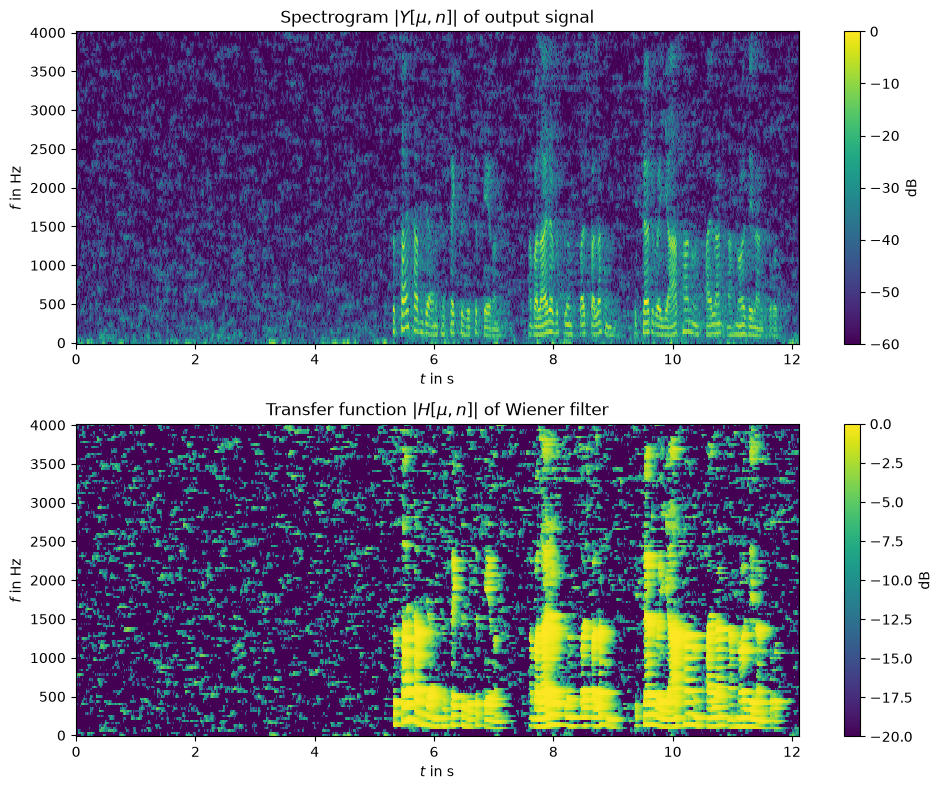

In [6]:
y, H = wiener_denoise(x, w, R, Pnn, alpha, Hmin)

plt.figure(figsize=(10, 8))
plt.subplot(211)
plot_spectrogram(stft(y, w, R), r"Spectrogram $|Y[\mu, n]|$ of output signal")
plt.subplot(212)
t = np.arange(H.shape[1]) * R / fs
plt.pcolormesh(t, f, 20 * np.log10(H), vmin=-20, vmax=0, shading="auto")
plt.title(r"Transfer function $|H[\mu, n]|$ of Wiener filter")
plt.xlabel(r"$t$ in s")
plt.ylabel(r"$f$ in Hz")
cb = plt.colorbar()
cb.set_label("dB")
plt.tight_layout()

The performance of the noise reduction can be quantified since the speech signal $s[k]$ and the noise $n[k]$ are known in this simulation. The SNR of the observed signal and the output signal are evaluated for the segment with speech activity $t \geq T_0$ as

\begin{equation}
\text{SNR}_x = 10 \log_{10} \frac{\sum_k s^2[k]}{\sum_k (x[k] - s[k])^2} \qquad \text{SNR}_y = 10 \log_{10} \frac{\sum_k s^2[k]}{\sum_k (y[k] - s[k])^2}
\end{equation}

Note, that the error $y[k] - s[k]$ comprises the residual noise as well as the distortions of the speech signal introduced by the filter. The attenuation of the noise is furthermore evaluated in the noise-only segment $t < T_0$.

In [7]:
def evaluate(y):
    # SNR in speech segment and noise attenuation in noise-only segment
    sp = slice(T0 * fs, None)
    no = slice(0, T0 * fs)
    SNRy = 10 * np.log10(np.sum(s[sp] ** 2) / np.sum((y[sp] - s[sp]) ** 2))
    att = 10 * np.log10(np.sum(x[no] ** 2) / np.sum(y[no] ** 2))
    return SNRy, att


SNRx = 10 * np.log10(np.sum(s[T0 * fs :] ** 2) / np.sum(n[T0 * fs :] ** 2))
SNRy, att = evaluate(y)
print("SNR of observed signal: {:5.2f} dB".format(SNRx))
print("SNR of output signal: {:5.2f} dB".format(SNRy))
print("noise attenuation in noise-only segment: {:5.2f} dB".format(att))

SNR of observed signal:  5.00 dB
SNR of output signal: 10.70 dB
noise attenuation in noise-only segment: 11.12 dB


Let's listen to the observed signal $x[k]$ and the output $y[k]$ of the Wiener filter. Both signals are scaled by the same factor in order to avoid clipping.

In [8]:
norm = 1.05 * np.max(np.abs(x))
sf.write("Wiener_speech_observed.wav", x / norm, fs)
sf.write("Wiener_speech_output.wav", y / norm, fs)

**Observed signal**

<audio src="./Wiener_speech_observed.wav" controls>Your browser does not support the audio element.</audio>[./Wiener_speech_observed.wav](./Wiener_speech_observed.wav)

**Output of Wiener filter**

<audio src="./Wiener_speech_output.wav" controls>Your browser does not support the audio element.</audio>[./Wiener_speech_output.wav](./Wiener_speech_output.wav)

### Discussion

The block-based Wiener filter discussed in this notebook is the classical approach to single-channel noise reduction. Its performance relies on several assumptions and approximations:

* **Stationary noise:** The noise PSD is estimated once from the initial noise-only segment. If the noise changes over time, e.g. a passing car, the estimate becomes inaccurate. Practical systems update the noise PSD continuously, e.g. during speech pauses detected by a voice activity detector or by tracking the minima of the PSD of the observed signal (*minimum statistics*).
* **Short-time stationarity of speech:** The PSD of the speech signal is assumed to be constant within one block. The block length $L$ constitutes a trade-off between this assumption and the frequency resolution.
* **Estimation of $\Phi_{xx}$:** The PSD of the observed signal can only be estimated from a few blocks. The resulting estimation errors cause musical noise, which is mitigated by smoothing and a spectral floor at the cost of less noise attenuation.
* **Cyclic convolution:** The multiplication $H[\mu, n] \cdot X[\mu, n]$ of DFT spectra corresponds to a cyclic convolution of the block with the impulse response of the filter. Time-domain aliasing is not prevented explicitly. Its effect is reduced by the synthesis window and by the smooth transfer functions resulting from the PSD estimates.

The Wiener filter is the optimal *linear* filter in the MMSE sense for WSS signals. Non-linear estimators that exploit the statistics of speech, as well as data-driven approaches based on deep neural networks, achieve a better performance in practice. Many of them however still rely on the STFT-based block processing and the time-frequency gain $H[\mu, n]$ introduced in this notebook.

**Exercise**

* Change the smoothing constant `alpha` and the spectral floor `Hmin`. How do they affect the SNR, the noise attenuation and the perceived quality of the output signal? Listen to the output for `alpha = 0` and `Hmin = 0`.
* Change the block length `L`. What happens for very short and very long blocks?
* Change the SNR `SNR` of the observed signal. How does the performance of the Wiener filter change?

Solution: For `alpha = 0` and `Hmin = 0` the residual noise exhibits strong musical noise. Increasing the smoothing constant $\alpha$ reduces the variance of the PSD estimate $\hat{\Phi}_{xx}[\mu, n]$ and hence the musical noise. However, for large values the estimate cannot follow the fast changes of the speech signal. Onsets of speech are attenuated and the noise is not suppressed directly after speech activity. Increasing the spectral floor $H_\text{min}$ reduces the musical noise and the distortions of the speech signal at the cost of a lower noise attenuation. For short blocks the frequency resolution is low, such that the harmonics of voiced speech cannot be resolved. For long blocks the assumption of short-time stationarity is violated, the time resolution decreases and speech onsets as well as transitions between phonemes are smeared over time. For lower SNR the speech components are increasingly masked by the noise and the Wiener filter attenuates them. The improvement of the SNR and the quality of the output decrease.

**Copyright**

This notebook is provided as [Open Educational Resource](https://en.wikipedia.org/wiki/Open_educational_resources). Feel free to use the notebook for your own purposes. The text is licensed under [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/), the code of the IPython examples under the [MIT license](https://opensource.org/licenses/MIT). Please attribute the work as follows: *Sascha Spors, Digital Signal Processing - Lecture notes featuring computational examples*.